# Clustering Lab: Customer Segmentation with k-means

We have mall customers and no labels telling us who belongs with whom. The goal of
**clustering** is to let the data group itself into segments we can act on.

We have the two tools
you use when you do **not** already know how many clusters to make:

- the **elbow method**, and
- the **silhouette score**.

Read the short notes between the cells; each one says both what the code does and why we do it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"
PALETTE = ["#00053E", "#FFC72C", "#2E8B8B", "#C05640", "#8E9BAE"]  # up to 5 clusters
print("Ready.")

Ready.


## Step 1: Load and explore

**Why:** always look before you cluster. We check the columns, the types, and the ranges,
because the ranges decide whether we need to scale (we do).

In [19]:
df = pd.read_csv("mall_customers.csv")
print("Shape:", df.shape)
df.head()

Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## Step 2: Pick features and scale

**Why these two features.** The dataset has Age, Annual Income, and Spending Score. For a
demo we cluster on **Annual Income** and **Spending Score** so the result plots directly in
2D and is easy to read. (With more features you cannot see the plot directly; you reduce it
with PCA first, as in the seeds example.)

**Why scale.** k-means measures distance, and income (about 15 to 137) has a far wider range
than spending score (1 to 99). Without scaling, income would dominate. `StandardScaler` puts
both on the same footing (mean 0, standard deviation 1).

In [ ]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].values

scaler = StandardScaler() # uses z_score = (data_point - mean)/std
Xs = scaler.fit_transform(X)      # scaled features that k-means will actually use # calculate the means and std then use those to calculate the z score for each data point
print("Scaled means (~0):", np.round(Xs.mean(axis=0), 3), " std (~1):", np.round(Xs.std(axis=0), 3))
Xs

Scaled means (~0): [-0. -0.]  std (~1): [1. 1.]


array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

## Step 3: How many clusters? Elbow + silhouette

We have no labels and no given k, so we try a range of k and let two measures guide us.

**Inertia and the elbow method.** Inertia is the total squared distance from each point to its
cluster's center, so it measures how tight the clusters are. It always drops as k grows (more
centers means points sit closer to one). The trick is to find the **elbow**, the k where the
drop suddenly flattens; adding clusters past there buys almost nothing.

**Silhouette score.** For each point it compares the average distance to points in its **own**
cluster against the average distance to points in the **nearest other** cluster. The value runs
from -1 to 1:

- near **1**: the point sits snugly inside its cluster, far from others (good),
- near **0**: the point is on the border between two clusters,
- **below 0**: the point is probably in the wrong cluster.

`silhouette_score` averages this over all points, so a **higher** average means better-separated
clusters. We pick the k with the highest silhouette, and we like it best when the elbow agrees.

 Hi, 5


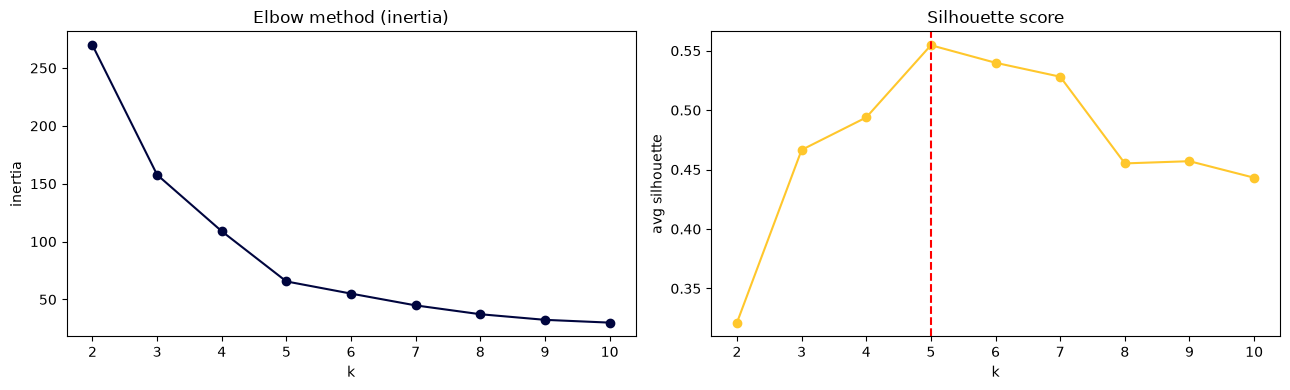

Silhouette by k: {2: 0.321, 3: 0.467, 4: 0.494, 5: 0.555, 6: 0.54, 7: 0.528, 8: 0.455, 9: 0.457, 10: 0.443}
Best k by silhouette: 5


In [ ]:
ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)                       # tightness, for the elbow
    sils.append(silhouette_score(Xs, km.labels_))      # separation, higher is better

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(list(ks), inertias, "o-", color=ETSU_NAVY)
ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia")

ax[1].plot(list(ks), sils, "o-", color=ETSU_GOLD)
ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("avg silhouette")


# retrieving the best k i.e. the cluster number in the list with highest silhouette score by indexing
best_k = list(ks)[int(np.argmax(sils))] # same as doing print([2, 3, 4, 5, 6, 7, 8, 9, 10][3]")

ax[1].axvline(best_k, color="red", linestyle="--")
plt.tight_layout(); plt.show()

print("Silhouette by k:", {k: round(s, 3) for k, s in zip(ks, sils)})
print("Best k by silhouette:", best_k)

Both agree on **k = 5**: the inertia curve bends there, and the silhouette score is highest
there. So we build 5 clusters.

## Step 4: Fit k-means with the chosen k

In [6]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
df["cluster"] = kmeans.labels_          # attach each customer's cluster id
df[["Annual Income (k$)", "Spending Score (1-100)", "cluster"]].head()

,Annual Income (k$),Spending Score (1-100),cluster
0,15,39,4
1,15,81,2
2,16,6,4
3,16,77,2
4,17,40,4


## Step 5: Visualize the segments

**Why plot in the original units.** We color each customer by its cluster but plot on the real
income and spending axes (not the scaled ones) so the chart is readable. The big X marks are
each cluster's average customer.

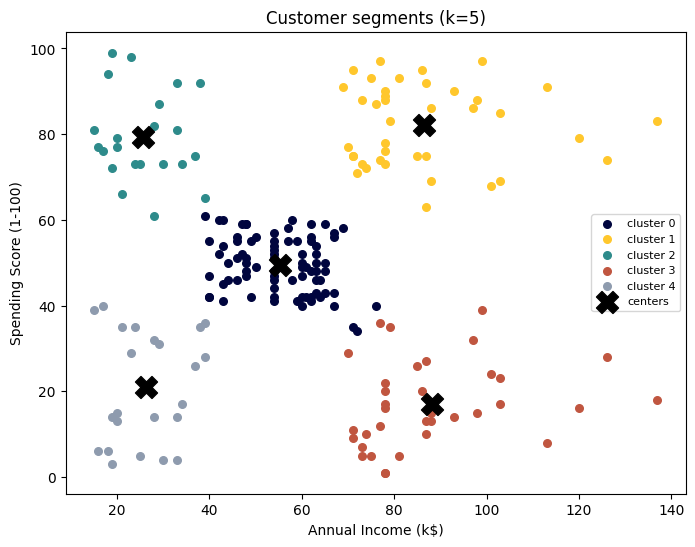

In [7]:
plt.figure(figsize=(8, 6))
for c in range(k):
    m = df["cluster"] == c
    plt.scatter(df.loc[m, "Annual Income (k$)"], df.loc[m, "Spending Score (1-100)"],
                s=30, color=PALETTE[c], label=f"cluster {c}")
# cluster centers back in original units
centers = df.groupby("cluster")[features].mean()
plt.scatter(centers[features[0]], centers[features[1]], s=250, marker="X",
            color="black", label="centers")
plt.xlabel("Annual Income (k$)"); plt.ylabel("Spending Score (1-100)")
plt.title("Customer segments (k=5)"); plt.legend(fontsize=8)
plt.show()

## Step 6: Profile and name the segments

**Why this is the real payoff.** Clusters are useless until you can say what each one *is* and
what to do about it. We summarize each cluster by its average income, average spending, and
size, then describe it in plain business language.

In [8]:
profile = df.groupby("cluster").agg(
    customers=("CustomerID", "count"),
    avg_income=("Annual Income (k$)", "mean"),
    avg_spending=("Spending Score (1-100)", "mean"),
).round(1)
profile

,customers,avg_income,avg_spending
cluster,,,
0,81,55.3,49.5
1,39,86.5,82.1
2,22,25.7,79.4
3,35,88.2,17.1
4,23,26.3,20.9


Reading the profile by **income level** and **spending level**, the five segments are the
classic mall picture:

- **High income, high spending:** the prime targets. They can spend and they do; focus loyalty and premium offers here.
- **High income, low spending:** earn well but hold back. The biggest untapped opportunity; find out what would get them to spend.
- **Low income, high spending:** spend freely relative to income. Responsive to deals, but watch value.
- **Low income, low spending:** budget-conscious. Low priority for premium pushes.
- **Middle income, middle spending:** the steady average majority.

That is a result a marketing team can act on, produced from data that had no labels at all.

## Takeaway

1. With no labels and no given k, use the **elbow** (tightness) and the **silhouette** (separation) together to choose k, and trust it most when they agree.
2. **Silhouette** also tells you *how good* the clustering is on its own, from -1 to 1, higher is better. It is the label-free stand-in for the accuracy-style checks we used in supervised learning.
3. The deliverable is the **segment profile and interpretation**, not just the cluster plot.
4. Here we clustered on 2 features so we could see it. With more features, scale them, cluster, and use **PCA** to view the result in 2D (as in the seeds demo).